# Chapter 4 — Building Models with Distance Metrics and Nearest Neighbors

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Chapter ini membahas keluarga model yang paling intuitif dalam machine learning: model berbasis **jarak** (*distance-based models*), dengan **k-Nearest Neighbors (KNN)** sebagai tokoh utamanya. Ide dasarnya sederhana — *titik data yang berdekatan cenderung memiliki label yang mirip* — tetapi di balik kesederhanaan itu ada banyak keputusan penting: metrik jarak apa yang dipakai, berapa banyak tetangga yang dilibatkan, bagaimana suara tetangga diberi bobot, bagaimana pengaruh skala fitur, serta bagaimana mengevaluasi model secara jujur.

**Daftar Isi**

1. Import Library
2. 4.1 Memahami k-Nearest Neighbors (KNN)
3. 4.2 Gambaran Umum Distance Metrics
4. 4.3 Hyperparameter Tuning pada KNN
5. 4.4 Mengevaluasi Performa KNN
6. Latihan — Practical Exercises with KNN Models (Exercise 1–3)
7. Ringkasan Chapter 4

> **Catatan:** Notebook ini mereproduksi seluruh kode resep pada Chapter 4 (mengikuti notebook resmi penerbit, dengan sedikit penyesuaian agar lebih jelas dan kompatibel dengan scikit-learn versi terbaru), lalu menjelaskan teori di balik setiap resep. Beberapa sel bertanda **(Tambahan)** ditambahkan untuk memperdalam pemahaman konsep (misalnya implementasi KNN manual, efek *feature scaling*, *curse of dimensionality*, dan KD-Tree/Ball-Tree). Penjelasan ditulis dalam Bahasa Indonesia dengan istilah teknis tetap dalam bahasa Inggris.

## Import Library

Library utama yang digunakan sepanjang chapter: `numpy` dan `pandas` untuk manipulasi data, `matplotlib` dan `seaborn` untuk visualisasi, `scipy` untuk perhitungan jarak, serta berbagai modul `scikit-learn` (`neighbors`, `datasets`, `model_selection`, `metrics`, `preprocessing`, `pipeline`).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import distance

import sklearn
from sklearn.datasets import load_iris, make_circles, load_breast_cancer, make_classification
from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score,
                                     learning_curve, validation_curve, StratifiedKFold)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, pairwise_distances, mean_squared_error)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 2024

print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

numpy       : 2.5.3
pandas      : 3.0.6
scikit-learn: 1.9.1


**Interpretasi:** Semua library berhasil di-import. Versi scikit-learn yang dipakai lebih baru daripada versi acuan buku (1.5), namun seluruh API KNN yang digunakan di chapter ini (`KNeighborsClassifier`, `GridSearchCV`, `learning_curve`, dll.) tetap stabil. Konstanta `RANDOM_STATE` dipakai agar hasil dapat direproduksi.

## 4.1 Memahami k-Nearest Neighbors (KNN)

**Teori:**

**KNN** adalah algoritma *supervised learning* yang bersifat **non-parametrik** dan **instance-based** (sering disebut juga *lazy learner*).

- *Non-parametrik*: model tidak mengasumsikan bentuk fungsi tertentu (misalnya garis lurus seperti regresi linear) maupun distribusi data tertentu. Kompleksitas model tumbuh seiring jumlah data.
- *Lazy / instance-based*: tahap `fit()` praktis hanya **menyimpan** data latih (ditambah membangun struktur indeks seperti KD-Tree). Semua komputasi "sebenarnya" terjadi saat prediksi.

**Aturan keputusan (klasifikasi).** Diberikan data latih $\mathcal{D}=\{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$ dan titik baru $\mathbf{x}$, hitung jarak $d(\mathbf{x}, \mathbf{x}_i)$ ke semua titik latih, lalu ambil himpunan $N_k(\mathbf{x})$ yang berisi $k$ titik terdekat. Kelas prediksi adalah hasil *majority vote*:

$$
\hat{y}(\mathbf{x}) = \arg\max_{c} \sum_{i \in N_k(\mathbf{x})} \mathbb{1}(y_i = c)
$$

Secara probabilistik, KNN mengestimasi probabilitas posterior kelas secara lokal:

$$
\hat{P}(y=c \mid \mathbf{x}) = \frac{1}{k}\sum_{i \in N_k(\mathbf{x})} \mathbb{1}(y_i = c)
$$

sehingga aturan di atas adalah pendekatan dari **Bayes optimal classifier** (memilih kelas dengan posterior terbesar). Nilai inilah yang dikembalikan oleh `predict_proba()`.

**Regresi KNN.** Untuk target kontinu, prediksi adalah rata-rata target tetangga: $\hat{y}(\mathbf{x}) = \frac{1}{k}\sum_{i \in N_k(\mathbf{x})} y_i$ (`KNeighborsRegressor`).

**Peran $k$ (bias–variance trade-off).**
- $k$ kecil (mis. $k=1$): batas keputusan sangat berliku, mengikuti noise → **variance tinggi, bias rendah** (rawan *overfitting*).
- $k$ besar: prediksi dirata-ratakan di wilayah luas → batas keputusan halus → **bias tinggi, variance rendah** (rawan *underfitting*). Jika $k=n$, model selalu memprediksi kelas mayoritas.
- Untuk klasifikasi biner, $k$ ganjil menghindari seri (*tie*).

**Hasil teoretis penting (Cover & Hart, 1967).** Untuk $n \to \infty$, error 1-NN dibatasi oleh $R^* \le R_{1NN} \le 2R^*(1-R^*)$ — yakni paling buruk sekitar dua kali error Bayes $R^*$. Jika $k\to\infty$ dan $k/n \to 0$, KNN bersifat **konsisten** (error-nya konvergen ke error Bayes).

**Kompleksitas.** Pelatihan $O(1)$ (brute force) sedangkan prediksi brute force membutuhkan $O(n\cdot p)$ per titik ($p$ = jumlah fitur). Inilah alasan struktur data seperti KD-Tree/Ball-Tree dipakai (dibahas di 4.2).

Pada resep ini kita memakai dataset **Iris** (150 sampel, 4 fitur numerik, 3 kelas) dan membaginya 80:20 menjadi data latih dan data uji.

In [2]:
# Memuat dataset Iris
iris = load_iris()
X = iris.data
y = iris.target

# Membagi data menjadi data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)

print("Ukuran X_train:", X_train.shape, "| Ukuran X_test:", X_test.shape)
print("Nama fitur   :", iris.feature_names)
print("Nama kelas   :", list(iris.target_names))
print("Distribusi kelas pada data latih:", np.bincount(y_train))

Ukuran X_train: (120, 4) | Ukuran X_test: (30, 4)
Nama fitur   : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nama kelas   : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Distribusi kelas pada data latih: [38 42 40]


Seperti model scikit-learn lainnya, KNN mengikuti pola API yang sama: buat objek estimator → `fit()` → `predict()`. Kita mulai dengan $k=3$.

In [3]:
# Membuat dan melatih model KNN dasar dengan k = 3
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Prediksi pada data uji
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


**(Tambahan) Membedah cara kerja KNN.** Sel berikut mengimplementasikan aturan keputusan KNN secara manual dengan NumPy (hitung jarak Euclidean → urutkan → ambil $k$ teratas → *majority vote*) dan membandingkannya dengan hasil scikit-learn. Kita juga melihat tetangga terdekat dari satu titik uji melalui `kneighbors()` serta estimasi posterior dari `predict_proba()`.

In [4]:
def knn_manual(X_tr, y_tr, X_te, k=3):
    # Implementasi KNN sederhana: brute force + majority vote
    preds = []
    for x in X_te:
        d = np.sqrt(((X_tr - x) ** 2).sum(axis=1))      # jarak Euclidean ke semua titik latih
        idx = np.argsort(d)[:k]                          # indeks k tetangga terdekat
        preds.append(np.bincount(y_tr[idx]).argmax())    # majority vote
    return np.array(preds)

y_pred_manual = knn_manual(X_train, y_train, X_test, k=3)
print("Prediksi manual identik dengan scikit-learn?", np.array_equal(y_pred_manual, y_pred))

# Melihat tetangga terdekat untuk satu titik uji
i = 0
dist, ind = knn.kneighbors(X_test[i:i + 1])
print(f"\nTitik uji ke-{i}: {X_test[i]} (label asli = {iris.target_names[y_test[i]]})")
print("Jarak ke 3 tetangga  :", np.round(dist[0], 3))
print("Label 3 tetangga     :", iris.target_names[y_train[ind[0]]])
print("predict_proba (posterior lokal):", np.round(knn.predict_proba(X_test[i:i + 1])[0], 3))

Prediksi manual identik dengan scikit-learn? True

Titik uji ke-0: [5.8 4.  1.2 0.2] (label asli = setosa)
Jarak ke 3 tetangga  : [0.412 0.469 0.557]
Label 3 tetangga     : ['setosa' 'setosa' 'setosa']
predict_proba (posterior lokal): [1. 0. 0.]


**(Tambahan) KNN untuk regresi dan efek $k$.** Untuk menunjukkan bahwa KNN juga dapat dipakai pada regresi — sekaligus memvisualisasikan *bias–variance trade-off* — kita memasang `KNeighborsRegressor` pada data sinus ber-noise dengan beberapa nilai $k$.

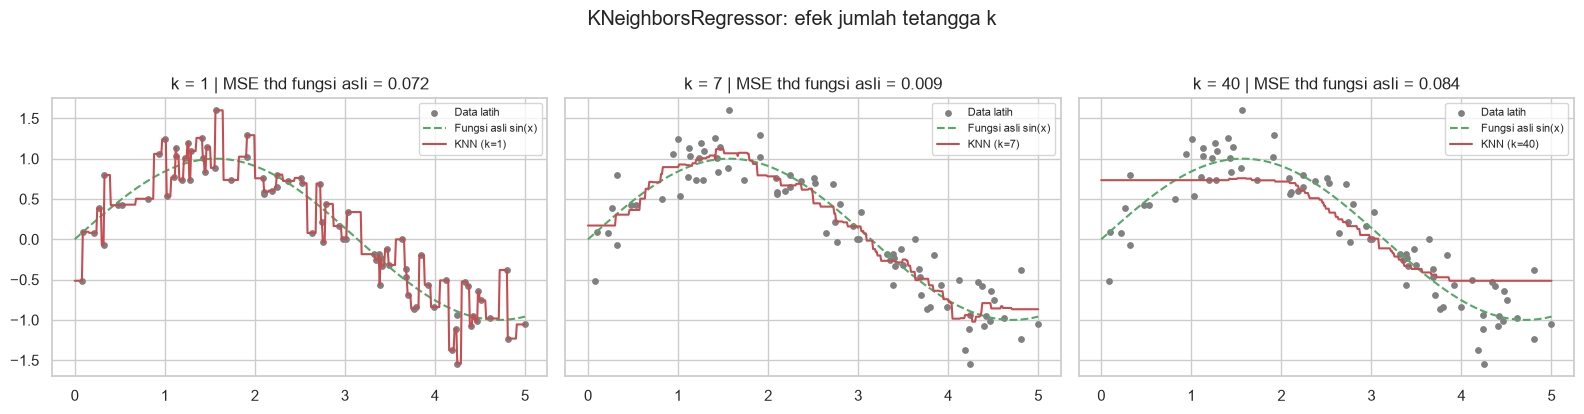

In [5]:
rng = np.random.RandomState(RANDOM_STATE)
X_reg = np.sort(rng.uniform(0, 5, 80))[:, None]
y_reg = np.sin(X_reg).ravel() + rng.normal(0, 0.25, X_reg.shape[0])
X_grid = np.linspace(0, 5, 500)[:, None]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, k in zip(axes, [1, 7, 40]):
    reg = KNeighborsRegressor(n_neighbors=k).fit(X_reg, y_reg)
    mse = mean_squared_error(np.sin(X_grid).ravel(), reg.predict(X_grid))
    ax.scatter(X_reg, y_reg, s=15, color="gray", label="Data latih")
    ax.plot(X_grid, np.sin(X_grid), "g--", label="Fungsi asli sin(x)")
    ax.plot(X_grid, reg.predict(X_grid), "r", label=f"KNN (k={k})")
    ax.set_title(f"k = {k} | MSE thd fungsi asli = {mse:.3f}")
    ax.legend(fontsize=8)
plt.suptitle("KNeighborsRegressor: efek jumlah tetangga k", y=1.03)
plt.tight_layout()
plt.show()

**Interpretasi:** Dataset Iris dibagi menjadi 120 sampel latih (distribusi kelas 38/42/40, cukup seimbang) dan 30 sampel uji. KNN dengan $k=3$ mencapai **accuracy 0,933** pada data uji, artinya 28 dari 30 bunga diklasifikasikan dengan benar; dua kesalahan terjadi antara *versicolor* dan *virginica* — dua spesies yang memang saling tumpang-tindih di ruang fitur, sementara *setosa* terpisah jelas. Implementasi manual (brute force + majority vote) menghasilkan prediksi **identik** dengan scikit-learn, membuktikan bahwa KNN memang sesederhana aturan keputusan di bagian teori. Untuk titik uji pertama (setosa), ketiga tetangganya berjarak 0,41–0,56 dan semuanya setosa sehingga `predict_proba` = [1, 0, 0] (posterior lokal 3/3). Pada plot regresi: $k=1$ mengikuti setiap noise (kurva bergerigi, MSE terhadap fungsi asli ≈ 0,072 → *variance* tinggi), $k=40$ terlalu halus dan meratakan puncak/lembah sinus (MSE ≈ 0,084 → *bias* tinggi), sedangkan $k=7$ paling dekat dengan fungsi sebenarnya (MSE ≈ 0,009). Ini ilustrasi langsung *bias–variance trade-off*.

## 4.2 Gambaran Umum Distance Metrics

**Teori:**

Karena KNN sepenuhnya bergantung pada konsep "dekat", pemilihan **fungsi jarak** sama pentingnya dengan pemilihan algoritma. Sebuah fungsi $d$ disebut **metrik** bila untuk semua $\mathbf{x},\mathbf{y},\mathbf{z}$ berlaku:

1. Non-negatif: $d(\mathbf{x},\mathbf{y}) \ge 0$
2. Identitas: $d(\mathbf{x},\mathbf{y}) = 0 \iff \mathbf{x}=\mathbf{y}$
3. Simetri: $d(\mathbf{x},\mathbf{y}) = d(\mathbf{y},\mathbf{x})$
4. Ketidaksamaan segitiga: $d(\mathbf{x},\mathbf{z}) \le d(\mathbf{x},\mathbf{y}) + d(\mathbf{y},\mathbf{z})$

Sifat ke-4 inilah yang memungkinkan KD-Tree/Ball-Tree memangkas pencarian.

**Metrik-metrik utama** (untuk $\mathbf{x},\mathbf{y}\in\mathbb{R}^p$):

| Metrik | Rumus | Karakteristik |
|---|---|---|
| **Minkowski** ($L_p$) | $d_p(\mathbf{x},\mathbf{y}) = \left(\sum_{j=1}^{p} \lvert x_j - y_j\rvert^{p}\right)^{1/p}$ | Bentuk umum; parameter `p` di scikit-learn |
| **Euclidean** ($L_2$, $p=2$) | $\sqrt{\sum_j (x_j-y_j)^2}$ | Jarak "garis lurus"; default KNN (`minkowski` dengan `p=2`); sensitif terhadap outlier karena selisih dikuadratkan |
| **Manhattan** ($L_1$, $p=1$) | $\sum_j \lvert x_j-y_j\rvert$ | Jarak "blok kota" (bergerak sejajar sumbu); lebih robust terhadap outlier; cocok untuk data berstruktur grid/sumbu |
| **Chebyshev** ($L_\infty$, $p\to\infty$) | $\max_j \lvert x_j-y_j\rvert$ | Hanya selisih terbesar yang dihitung |
| **Cosine distance** | $1 - \dfrac{\mathbf{x}^\top\mathbf{y}}{\lVert\mathbf{x}\rVert_2\,\lVert\mathbf{y}\rVert_2}$ | Mengukur perbedaan **arah**, bukan besaran; populer untuk teks (TF-IDF) dan embedding. Secara formal bukan metrik (melanggar ketidaksamaan segitiga) |
| **Mahalanobis** | $\sqrt{(\mathbf{x}-\mathbf{y})^\top \Sigma^{-1}(\mathbf{x}-\mathbf{y})}$ | Memperhitungkan skala & korelasi antar fitur melalui kovarians $\Sigma$ |
| **Hamming** | $\frac{1}{p}\sum_j \mathbb{1}(x_j\ne y_j)$ | Untuk data kategorikal/biner |

Secara geometris, "bola satuan" $\{\mathbf{x}: d(\mathbf{0},\mathbf{x})\le 1\}$ berbentuk belah ketupat untuk $L_1$, lingkaran untuk $L_2$, dan persegi untuk $L_\infty$. Karena itu metrik yang berbeda menghasilkan **himpunan tetangga yang berbeda**, dan pada akhirnya batas keputusan yang berbeda. Perlu dicatat juga bahwa $d_\infty \le d_2 \le d_1$ untuk pasangan titik yang sama.

**Pentingnya feature scaling.** Semua metrik $L_p$ menjumlahkan selisih antar fitur secara langsung, sehingga fitur dengan rentang nilai besar (mis. "gaji" dalam jutaan) akan mendominasi fitur berskala kecil (mis. "umur"). Standardisasi $z_j = (x_j-\mu_j)/\sigma_j$ (`StandardScaler`) membuat setiap fitur berkontribusi setara. Scaler harus di-*fit* hanya pada data latih untuk menghindari *data leakage*.

**Curse of dimensionality.** Pada dimensi tinggi, jarak kehilangan daya pembeda: untuk titik acak, rasio $\dfrac{d_{\max}-d_{\min}}{d_{\min}} \to 0$ ketika $p\to\infty$ — semua titik tampak "sama jauhnya". Selain itu, untuk menangkap fraksi $r$ data dalam hiperkubus satuan dibutuhkan sisi sepanjang $r^{1/p}$; dengan $p=10$, menangkap 10% data memerlukan sisi $\approx 0{,}80$ dari rentang setiap fitur, sehingga "tetangga" sebenarnya tidak lokal lagi. Akibatnya KNN memerlukan reduksi dimensi/seleksi fitur pada data berdimensi tinggi.

**Struktur pencarian tetangga.** Parameter `algorithm` pada scikit-learn:
- `brute`: menghitung semua jarak, $O(np)$ per query; efisien untuk data kecil atau dimensi sangat tinggi.
- `kd_tree`: membagi ruang secara rekursif dengan hyperplane sejajar sumbu (median per fitur). Query rata-rata $\approx O(p\log n)$ pada dimensi rendah (kurang efektif bila $p \gtrsim 20$).
- `ball_tree`: membagi data menjadi hipersfer bersarang (pusat + radius). Dengan ketidaksamaan segitiga, satu *ball* bisa dilewati bila $d(\mathbf{q},\mathbf{c}) - r > d_{k\text{-terbaik}}$. Lebih tahan terhadap dimensi tinggi dan mendukung lebih banyak metrik.
- `auto` (default): scikit-learn memilih otomatis berdasarkan ukuran data, dimensi, dan metrik.

Distance metrics juga menjadi fondasi algoritma *unsupervised* seperti **K-Means**, yang meminimalkan *within-cluster sum of squares* $J=\sum_{c=1}^{K}\sum_{\mathbf{x}_i\in C_c}\lVert \mathbf{x}_i-\boldsymbol{\mu}_c\rVert_2^2$ — sekali lagi berbasis jarak Euclidean.

Pada resep buku, dua dataset sintetis dibuat untuk membandingkan metrik: **noisy circles** (`make_circles`, struktur radial yang secara alami cocok dengan Euclidean) dan **checkerboard** (pola papan catur pada grid yang sejajar sumbu, cocok dengan Manhattan).

**(Tambahan) Menghitung jarak secara manual.** Sebelum masuk resep, kita verifikasi rumus-rumus di atas pada dua vektor sederhana, dan memastikan hasilnya sama dengan `scipy.spatial.distance`.

In [6]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, 0.0, 3.5])

manual = {
    "euclidean (L2)":  np.sqrt(np.sum((a - b) ** 2)),
    "manhattan (L1)":  np.sum(np.abs(a - b)),
    "minkowski p=3":   np.sum(np.abs(a - b) ** 3) ** (1 / 3),
    "chebyshev (Linf)": np.max(np.abs(a - b)),
    "cosine":          1 - a @ b / (np.linalg.norm(a) * np.linalg.norm(b)),
}
scipy_vals = {
    "euclidean (L2)":  distance.euclidean(a, b),
    "manhattan (L1)":  distance.cityblock(a, b),
    "minkowski p=3":   distance.minkowski(a, b, p=3),
    "chebyshev (Linf)": distance.chebyshev(a, b),
    "cosine":          distance.cosine(a, b),
}
df_dist = pd.DataFrame({"manual": manual, "scipy": scipy_vals}).round(4)
df_dist

,manual,scipy
euclidean (L2),3.6401,3.6401
manhattan (L1),5.5000,5.5000
minkowski p=3,3.2750,3.2750
chebyshev (Linf),3.0000,3.0000
cosine,0.2709,0.2709


Langkah pertama resep: membuat dua dataset sintetis. Pada versi asli, `make_circles` tidak diberi `random_state`; di sini ditambahkan `random_state=2024` agar hasil dapat direproduksi. Dataset checkerboard (pada kode asli diberi nama variabel `X_moons`/`y_moons`, nama tersebut dipertahankan) dibuat dari grid $17\times17$ titik pada $[0,4]^2$ dengan label $(\lfloor x\rfloor + \lfloor y\rfloor) \bmod 2$.

In [7]:
# Membuat dua dataset sintetis yang menonjolkan perbedaan metrik jarak
n_samples = 300

# Dataset lingkaran dengan noise tinggi (diharapkan Euclidean bekerja lebih baik)
X_circles, y_circles = make_circles(n_samples=n_samples, noise=0.3, factor=0.3,
                                    random_state=2024)
X_circles_train, X_circles_test, y_circles_train, y_circles_test = train_test_split(
    X_circles, y_circles, test_size=0.2, random_state=2024
)

# Dataset pola checkerboard (diharapkan Manhattan bekerja lebih baik)
x = np.linspace(0, 4, int(np.sqrt(n_samples)))
y_ = np.linspace(0, 4, int(np.sqrt(n_samples)))   # pakai y_ agar tidak menimpa label Iris `y`
xx, yy = np.meshgrid(x, y_)
X_moons = np.column_stack((xx.ravel(), yy.ravel()))
y_moons = np.mod(np.floor(xx.ravel()) + np.floor(yy.ravel()), 2)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=2024
)

print("Circles     :", X_circles.shape, "| kelas:", np.bincount(y_circles))
print("Checkerboard:", X_moons.shape, "| kelas:", np.bincount(y_moons.astype(int)))

Circles     : (300, 2) | kelas: [150 150]
Checkerboard: (289, 2) | kelas: [145 144]


Selanjutnya, untuk setiap metrik (`euclidean`, `manhattan`, `minkowski`) kita latih KNN ($k=3$) pada kedua dataset, catat akurasinya, dan visualisasikan dataset beserta akurasi per metrik.

           circles  moons
euclidean    0.783  0.759
manhattan    0.767  0.793
minkowski    0.783  0.759


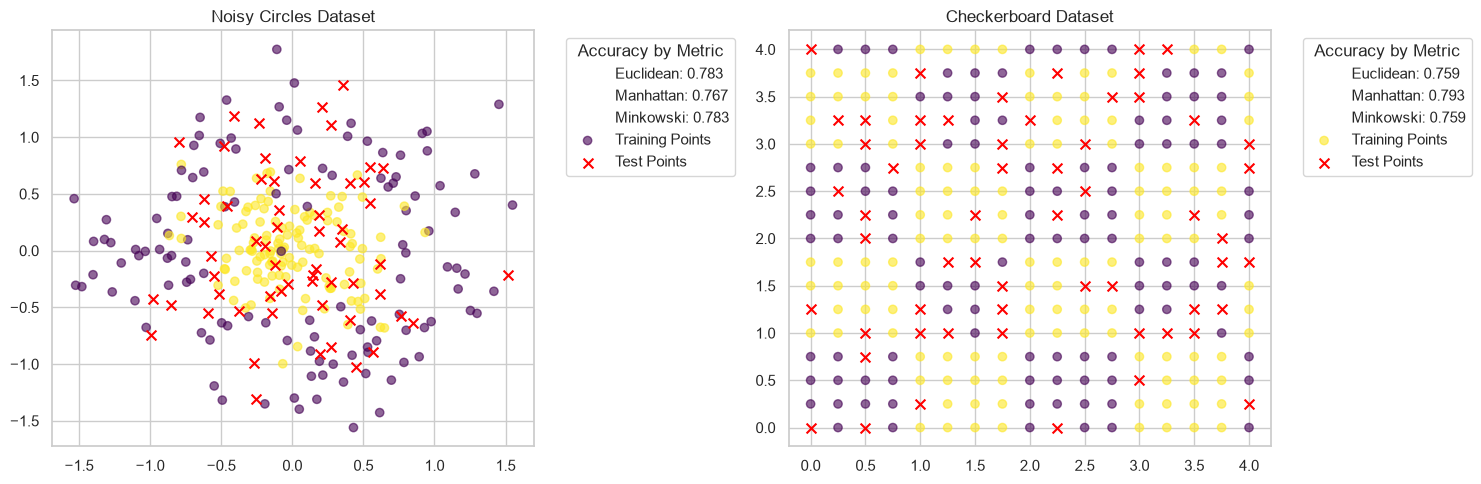

In [8]:
# Membandingkan beberapa metrik jarak pada kedua dataset
metrics = ['euclidean', 'manhattan', 'minkowski']
results = {'circles': {}, 'moons': {}}

for metric in metrics:
    # Uji pada dataset "circles"
    knn_circles = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_circles.fit(X_circles_train, y_circles_train)
    y_pred_circles = knn_circles.predict(X_circles_test)
    results['circles'][metric] = accuracy_score(y_circles_test, y_pred_circles)

    # Uji pada dataset checkerboard ("moons")
    knn_moons = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_moons.fit(X_moons_train, y_moons_train)
    y_pred_moons = knn_moons.predict(X_moons_test)
    results['moons'][metric] = accuracy_score(y_moons_test, y_pred_moons)

print(pd.DataFrame(results).round(3))

# Pengaturan plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot dataset circles
scatter1_train = ax1.scatter(X_circles_train[:, 0], X_circles_train[:, 1], c=y_circles_train,
                             cmap='viridis', alpha=0.6, label='Training Points')
scatter1_test = ax1.scatter(X_circles_test[:, 0], X_circles_test[:, 1], color='red',
                            marker='x', s=50, label='Test Points')
ax1.set_title('Noisy Circles Dataset')

# Garis "dummy" agar akurasi tampil di legend
lines1 = [plt.Line2D([0], [0], color='white') for _ in metrics]
legend_text1 = [
    f"Euclidean: {results['circles']['euclidean']:.3f}",
    f"Manhattan: {results['circles']['manhattan']:.3f}",
    f"Minkowski: {results['circles']['minkowski']:.3f}"
]
ax1.legend(lines1 + [scatter1_train, scatter1_test], legend_text1 + ['Training Points', 'Test Points'],
           title='Accuracy by Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot dataset checkerboard
scatter2_train = ax2.scatter(X_moons_train[:, 0], X_moons_train[:, 1], c=y_moons_train,
                             cmap='viridis', alpha=0.6, label='Training Points')
scatter2_test = ax2.scatter(X_moons_test[:, 0], X_moons_test[:, 1], color='red',
                            marker='x', s=50, label='Test Points')
ax2.set_title('Checkerboard Dataset')

lines2 = [plt.Line2D([0], [0], color='white') for _ in metrics]
legend_text2 = [
    f"Euclidean: {results['moons']['euclidean']:.3f}",
    f"Manhattan: {results['moons']['manhattan']:.3f}",
    f"Minkowski: {results['moons']['minkowski']:.3f}"
]
ax2.legend(lines2 + [scatter2_train, scatter2_test], legend_text2 + ['Training Points', 'Test Points'],
           title='Accuracy by Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

**(Tambahan) Visualisasi batas keputusan per metrik.** Angka akurasi pada test set kecil (60 titik) mudah berubah karena kebetulan. Untuk melihat perbedaan metrik secara lebih langsung, kita gambar *decision boundary* KNN ($k=3$) dengan $L_1$, $L_2$, dan $L_\infty$ pada dataset circles, serta akurasi 5-fold cross-validation pada seluruh data.

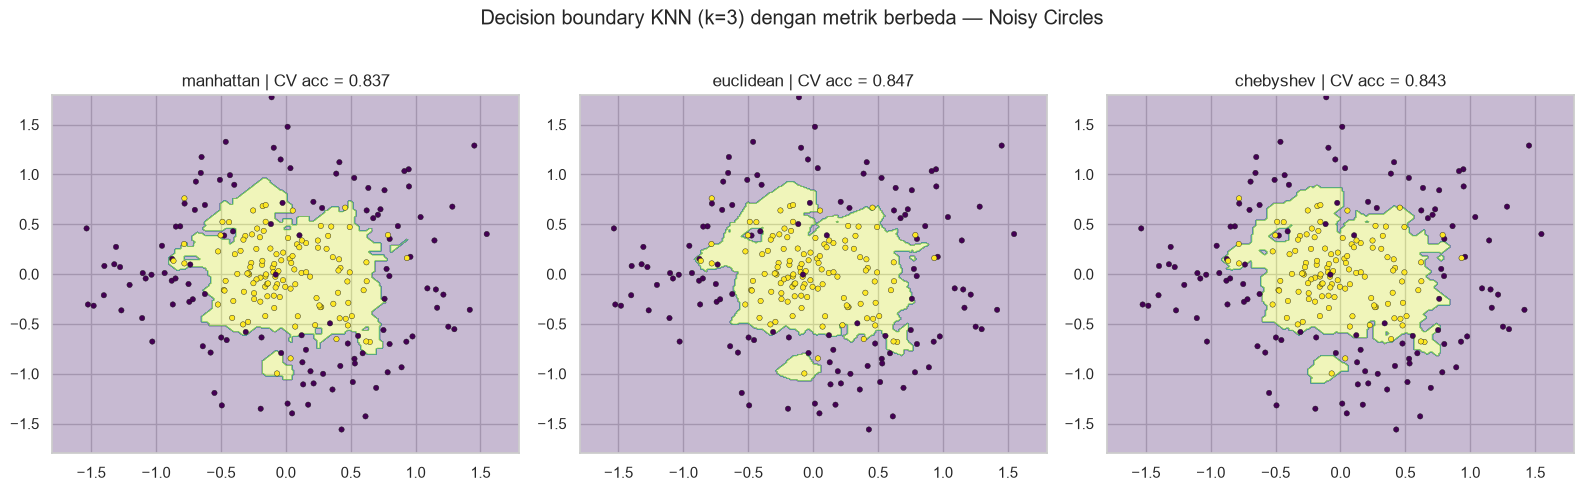

In [9]:
xx_g, yy_g = np.meshgrid(np.linspace(-1.8, 1.8, 300), np.linspace(-1.8, 1.8, 300))
grid = np.c_[xx_g.ravel(), yy_g.ravel()]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, metric in zip(axes, ['manhattan', 'euclidean', 'chebyshev']):
    model = KNeighborsClassifier(n_neighbors=3, metric=metric).fit(X_circles_train, y_circles_train)
    Z = model.predict(grid).reshape(xx_g.shape)
    cv_acc = cross_val_score(KNeighborsClassifier(n_neighbors=3, metric=metric),
                             X_circles, y_circles, cv=cv5).mean()
    ax.contourf(xx_g, yy_g, Z, alpha=0.3, cmap='viridis')
    ax.scatter(X_circles_train[:, 0], X_circles_train[:, 1], c=y_circles_train, cmap='viridis',
               s=15, edgecolor='k', linewidth=0.3)
    ax.set_title(f"{metric} | CV acc = {cv_acc:.3f}")
plt.suptitle("Decision boundary KNN (k=3) dengan metrik berbeda — Noisy Circles", y=1.02)
plt.tight_layout()
plt.show()

**(Tambahan) Efek feature scaling.** Kita kalikan satu fitur Iris dengan 1000 (seolah-olah satuannya berubah dari meter ke milimeter) lalu bandingkan akurasi cross-validation KNN tanpa dan dengan `StandardScaler`. Scaler dimasukkan ke dalam `Pipeline` agar di-*fit* ulang pada setiap fold (tanpa leakage).

In [10]:
X_distorted = X.copy()
X_distorted[:, 1] = X_distorted[:, 1] * 1000   # sepal width diubah skalanya

skenario = {
    "Iris asli, tanpa scaling":          (X, KNeighborsClassifier(n_neighbors=5)),
    "Fitur ke-2 x1000, tanpa scaling":   (X_distorted, KNeighborsClassifier(n_neighbors=5)),
    "Fitur ke-2 x1000, StandardScaler":  (X_distorted, make_pipeline(StandardScaler(),
                                                                    KNeighborsClassifier(n_neighbors=5))),
}
for nama, (data, model) in skenario.items():
    skor = cross_val_score(model, data, y, cv=cv5)
    print(f"{nama:<36}: CV accuracy = {skor.mean():.3f} ± {skor.std():.3f}")

Iris asli, tanpa scaling            : CV accuracy = 0.987 ± 0.016
Fitur ke-2 x1000, tanpa scaling     : CV accuracy = 0.713 ± 0.045
Fitur ke-2 x1000, StandardScaler    : CV accuracy = 0.953 ± 0.034


**(Tambahan) Curse of dimensionality.** Untuk titik acak uniform di hiperkubus $[0,1]^p$, kita ukur rasio kontras $\dfrac{d_{\max}-d_{\min}}{d_{\min}}$ dari sebuah titik query terhadap 1000 titik lain, untuk berbagai dimensi $p$.

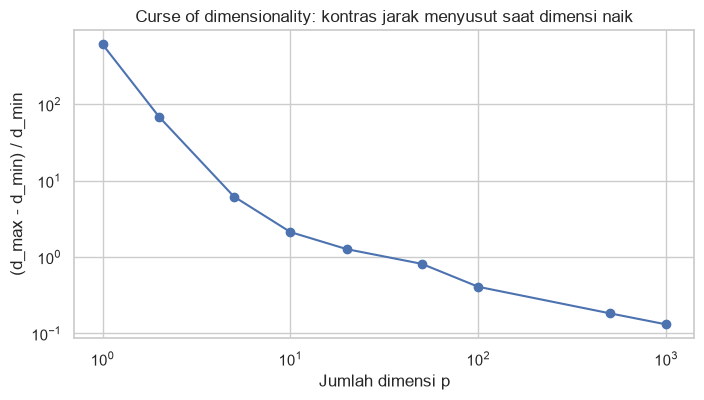

            1       2      5      10     20     50     100    500    1000
kontras  610.061  68.572  6.209  2.126  1.269  0.816  0.408  0.184  0.131


In [11]:
rng = np.random.RandomState(RANDOM_STATE)
dims = [1, 2, 5, 10, 20, 50, 100, 500, 1000]
kontras = []
for p in dims:
    pts = rng.uniform(size=(1000, p))
    q = rng.uniform(size=(1, p))
    d = pairwise_distances(q, pts, metric='euclidean').ravel()
    kontras.append((d.max() - d.min()) / d.min())

plt.figure(figsize=(8, 4))
plt.loglog(dims, kontras, 'o-')
plt.xlabel("Jumlah dimensi p")
plt.ylabel("(d_max - d_min) / d_min")
plt.title("Curse of dimensionality: kontras jarak menyusut saat dimensi naik")
plt.show()
print(pd.Series(np.round(kontras, 3), index=dims, name="kontras").to_frame().T)

**(Tambahan) KD-Tree vs Ball-Tree vs Brute force.** Semua algoritma pencarian menghasilkan tetangga yang **sama persis** (pencarian eksak); bedanya hanya pada kecepatan. Kita bandingkan waktu query pada data acak berdimensi rendah dan tinggi.

In [12]:
rng = np.random.RandomState(RANDOM_STATE)
rows = []
for p in [3, 50]:
    X_big = rng.normal(size=(20000, p))
    X_q = rng.normal(size=(2000, p))
    idx_ref = None
    for algo in ['brute', 'kd_tree', 'ball_tree']:
        nn = KNeighborsClassifier(n_neighbors=5, algorithm=algo).fit(X_big, np.zeros(len(X_big)))
        t0 = time.perf_counter()
        _, idx = nn.kneighbors(X_q)
        t = time.perf_counter() - t0
        sama = True if idx_ref is None else np.array_equal(np.sort(idx, 1), np.sort(idx_ref, 1))
        idx_ref = idx if idx_ref is None else idx_ref
        rows.append({"dimensi": p, "algorithm": algo, "waktu query (s)": round(t, 3),
                     "tetangga sama dgn brute": sama})
pd.DataFrame(rows)

,dimensi,algorithm,waktu query (s),tetangga sama dgn brute
0,3,brute,0.122,True
1,3,kd_tree,0.034,True
2,3,ball_tree,0.142,True
3,50,brute,0.112,True
4,50,kd_tree,5.262,True
5,50,ball_tree,4.291,True


**Interpretasi:** Tabel perhitungan manual cocok sempurna dengan SciPy (mis. Euclidean 3,640, Manhattan 5,500, Chebyshev 3,000), sekaligus memperlihatkan urutan $d_\infty \le d_2 \le d_1$. Pada resep utama, dataset *circles* memberi accuracy **0,783** untuk Euclidean dan Minkowski versus **0,767** untuk Manhattan, sedangkan pada *checkerboard* Manhattan unggul (**0,793** vs 0,759). Arah hasil ini sesuai intuisi geometris: struktur radial cocok dengan bola $L_2$, pola grid sejajar sumbu cocok dengan $L_1$. Perhatikan bahwa hasil Euclidean dan Minkowski **selalu identik** karena default `metric='minkowski'` memakai `p=2`. Namun selisihnya hanya 1–2 titik pada test set berukuran 58–60, sehingga harus ditafsirkan hati-hati; pada 5-fold CV seluruh data *circles*, ketiga metrik ($L_1$ 0,837, $L_2$ 0,847, $L_\infty$ 0,843) hampir setara dan batas keputusannya terlihat mirip, hanya berbeda di detail tepi. Eksperimen scaling menunjukkan efek yang jauh lebih dramatis: memperbesar satu fitur 1000× menjatuhkan CV accuracy dari 0,987 ke **0,713** karena jarak praktis hanya ditentukan fitur itu; `StandardScaler` memulihkannya ke 0,953 (sedikit di bawah aslinya karena standardisasi juga mengubah bobot relatif fitur lain dibanding data asli). Plot *curse of dimensionality* memperlihatkan rasio kontras $(d_{max}-d_{min})/d_{min}$ menyusut dari ratusan pada $p=1$ menjadi sekitar 0,13 pada $p=1000$ — di dimensi tinggi titik terjauh hanya ~13% lebih jauh dari titik terdekat. Terakhir, benchmark pencarian menunjukkan ketiga algoritma menemukan tetangga **yang sama persis**; pada 3 dimensi KD-Tree jauh lebih cepat daripada brute force, sedangkan pada 50 dimensi KD-Tree dan Ball-Tree justru jauh lebih lambat daripada brute force (pemangkasan pohon tidak efektif lagi, sementara brute force memanfaatkan operasi matriks yang teroptimasi). Angka waktu persisnya bergantung pada mesin, tetapi polanya konsisten dengan teori.

## 4.3 Hyperparameter Tuning pada KNN

**Teori:**

KNN hampir tidak memiliki parameter yang "dipelajari"; perilakunya ditentukan oleh **hyperparameter**:

1. **`n_neighbors` ($k$)** — mengatur bias–variance trade-off seperti dijelaskan di 4.1.
2. **`weights`** — cara menggabungkan suara tetangga:
   - `'uniform'`: setiap tetangga berbobot sama, $w_i = 1$.
   - `'distance'`: bobot berbanding terbalik dengan jarak, $w_i = 1/d(\mathbf{x},\mathbf{x}_i)$, sehingga aturan keputusannya menjadi
   $$\hat{y}(\mathbf{x}) = \arg\max_c \sum_{i\in N_k(\mathbf{x})} w_i\,\mathbb{1}(y_i=c), \qquad \hat{y}_{\text{reg}}(\mathbf{x}) = \frac{\sum_i w_i y_i}{\sum_i w_i}.$$
   Tetangga yang sangat dekat lebih berpengaruh, sehingga model kurang sensitif terhadap pilihan $k$ yang terlalu besar. Konsekuensinya: pada data latih sendiri, akurasi selalu 100% (jarak ke diri sendiri = 0 → bobot tak hingga), jadi evaluasi wajib di data yang tidak dilihat.
3. **`metric`** (dan `p`) — definisi jarak (4.2).

**Grid Search** mencoba **semua kombinasi** pada grid hyperparameter $\Theta = \Theta_k \times \Theta_w \times \Theta_m$ (di sini $5\times2\times2 = 20$ kombinasi) dan memilih

$$
\theta^* = \arg\max_{\theta\in\Theta} \; \frac{1}{K}\sum_{f=1}^{K} \text{Score}\big(h_\theta^{(-f)},\, \mathcal{D}_f\big)
$$

dengan **K-fold cross-validation**: data latih dibagi $K$ lipatan, model $h_\theta^{(-f)}$ dilatih pada $K-1$ lipatan dan dinilai pada lipatan ke-$f$, lalu skornya dirata-rata. Untuk klasifikasi, scikit-learn otomatis memakai `StratifiedKFold` (proporsi kelas tiap fold dijaga). Dengan `cv=5` dan 20 kombinasi, total ada 100 kali pelatihan — mahal untuk grid besar, sehingga alternatifnya adalah `RandomizedSearchCV` atau `HalvingGridSearchCV`.

Hal penting: test set **tidak boleh** dipakai saat tuning; ia disimpan untuk estimasi akhir performa (*generalization*). Setelah pencarian selesai, `GridSearchCV` (dengan `refit=True`) melatih ulang model terbaik pada seluruh data latih — tersedia sebagai `best_estimator_`.

In [13]:
# Membuat KNN classifier
knn = KNeighborsClassifier()

# Mendefinisikan grid parameter
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Membuat objek grid search (5-fold CV)
grid_search = GridSearchCV(
    knn, param_grid, cv=5, scoring='accuracy'
)

# Fit grid search pada data latih Iris
grid_search.fit(X_train, y_train)

# Menampilkan parameter dan skor terbaik
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.9916666666666668


**(Tambahan) Melihat seluruh hasil grid.** `cv_results_` menyimpan skor setiap kombinasi. Menampilkan beberapa peringkat teratas membantu melihat apakah pemenang benar-benar unggul atau hanya seri dengan banyak kombinasi lain.

,param_n_neighbors,param_weights,param_metric,mean_test_score,std_test_score,rank_test_score
0,9,uniform,euclidean,0.991667,0.016667,1
1,9,distance,euclidean,0.991667,0.016667,1
2,3,uniform,euclidean,0.983333,0.020412,3
3,3,distance,euclidean,0.983333,0.020412,3
4,5,distance,euclidean,0.983333,0.020412,3
5,5,uniform,euclidean,0.983333,0.020412,3
6,7,distance,euclidean,0.983333,0.020412,3
7,7,uniform,euclidean,0.983333,0.020412,3
8,11,uniform,euclidean,0.983333,0.020412,3
9,11,distance,euclidean,0.983333,0.020412,3


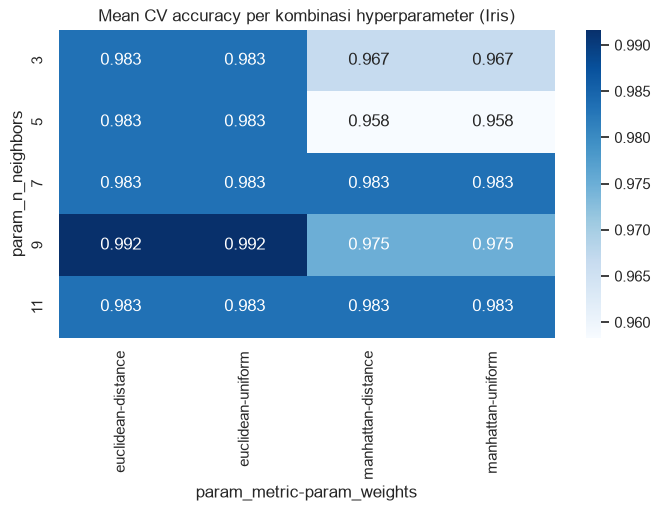

In [14]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cols = ['param_n_neighbors', 'param_weights', 'param_metric', 'mean_test_score', 'std_test_score', 'rank_test_score']
display(cv_res[cols].sort_values('rank_test_score').head(10).reset_index(drop=True))

# Heatmap rata-rata skor CV untuk setiap kombinasi
pivot = cv_res.pivot_table(index='param_n_neighbors',
                           columns=['param_metric', 'param_weights'],
                           values='mean_test_score')
plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='Blues')
plt.title('Mean CV accuracy per kombinasi hyperparameter (Iris)')
plt.show()

**(Tambahan) Validation curve terhadap $k$.** Kurva akurasi latih vs validasi sebagai fungsi $k$ memperlihatkan *bias–variance trade-off* secara langsung.

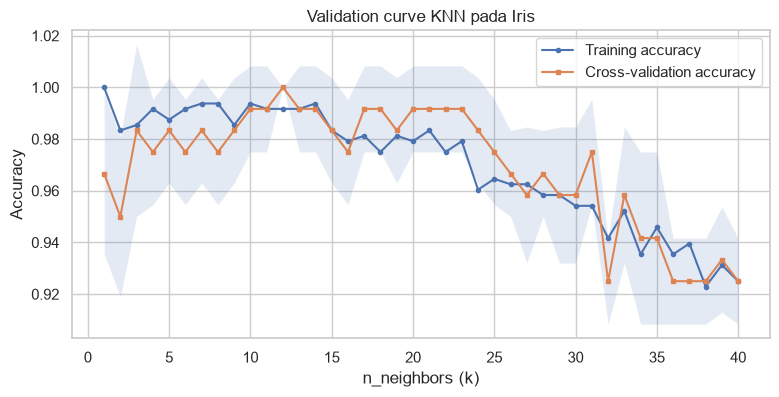

k dengan CV accuracy tertinggi: 12 | skor: 1.0


In [15]:
k_range = np.arange(1, 41)
train_sc, val_sc = validation_curve(
    KNeighborsClassifier(), X_train, y_train,
    param_name='n_neighbors', param_range=k_range, cv=cv5
)
plt.figure(figsize=(9, 4))
plt.plot(k_range, train_sc.mean(1), 'o-', ms=3, label='Training accuracy')
plt.plot(k_range, val_sc.mean(1), 's-', ms=3, label='Cross-validation accuracy')
plt.fill_between(k_range, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), alpha=0.15)
plt.xlabel('n_neighbors (k)')
plt.ylabel('Accuracy')
plt.title('Validation curve KNN pada Iris')
plt.legend()
plt.show()
print("k dengan CV accuracy tertinggi:", k_range[val_sc.mean(1).argmax()],
      "| skor:", round(val_sc.mean(1).max(), 3))

**Interpretasi:** Grid search memilih **`metric='euclidean'`, `n_neighbors=9`, `weights='uniform'`** dengan rata-rata CV accuracy **0,992**. Tabel peringkat memperlihatkan bahwa pemenangnya seri dengan versi `weights='distance'` (skor identik), dan banyak kombinasi Euclidean lain hanya berselisih 0,008 (setara satu sampel pada satu fold). Heatmap menunjukkan kombinasi Euclidean konsisten sedikit lebih baik daripada Manhattan pada Iris. Artinya, pada dataset sekecil dan semudah ini, permukaan skor relatif datar; pilihan "terbaik" sebagian ditentukan oleh urutan grid saat seri. Validation curve menegaskan pola bias–variance: pada $k=1$ akurasi latih 1,0 tetapi validasi lebih rendah (0,967); pada rentang $k\approx 9$–$23$ akurasi validasi mencapai puncaknya (0,98–1,0; tertinggi di $k=12$); setelah $k>25$ kedua kurva menurun bersamaan (hingga ~0,93) karena model mulai *underfit* — tetangga dari kelas lain ikut masuk voting.

## 4.4 Mengevaluasi Performa KNN

**Teori:**

Satu angka akurasi pada test set kecil belum cukup untuk menilai model. Resep ini memakai tiga alat:

**1. Cross-validation scores.** Rata-rata $\bar{s}=\frac{1}{K}\sum_f s_f$ memberi estimasi performa, sedangkan simpangan baku $\sigma_s$ menunjukkan **stabilitas** model terhadap variasi data. Skor yang sangat bervariasi antar fold menandakan model sensitif terhadap data latih tertentu.

**2. Learning curve.** Plot skor latih dan skor validasi sebagai fungsi ukuran data latih $n$:
- Kedua kurva rendah dan berdekatan → **high bias** (underfitting); menambah data tidak banyak membantu, perlu model lebih kompleks.
- Skor latih tinggi, skor validasi jauh lebih rendah → **high variance** (overfitting); menambah data atau regularisasi (untuk KNN: menaikkan $k$) biasanya membantu.
- Kedua kurva konvergen di nilai tinggi → model sudah baik; data tambahan memberi hasil yang semakin kecil (*diminishing returns*).

**3. Confusion matrix & classification report.** Confusion matrix $C$ berisi $C_{ij}$ = jumlah sampel kelas asli $i$ yang diprediksi sebagai kelas $j$; diagonal = prediksi benar. Dari sudut pandang satu kelas $c$ (one-vs-rest) didefinisikan TP, FP, FN, TN, lalu:

$$
\text{Precision}_c = \frac{TP}{TP+FP}, \qquad
\text{Recall}_c = \frac{TP}{TP+FN}, \qquad
F_1 = 2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}
$$

$$
\text{Accuracy} = \frac{\sum_i C_{ii}}{\sum_{i,j} C_{ij}}
$$

- *Precision*: dari semua yang diprediksi kelas $c$, berapa yang benar (mengukur biaya *false positive*).
- *Recall* (sensitivity): dari semua anggota kelas $c$, berapa yang tertangkap (mengukur biaya *false negative*).
- *F1*: rata-rata harmonik keduanya; tinggi hanya jika keduanya tinggi.
- **Macro average** = rata-rata sederhana antar kelas (setiap kelas setara), **weighted average** = rata-rata berbobot jumlah sampel (*support*) — keduanya berbeda jauh bila kelas tidak seimbang. Baris *accuracy* pada laporan adalah satu nilai global.

In [16]:
# Library evaluasi (sudah di-import di awal; diulang di sini mengikuti struktur resep)
from sklearn.model_selection import learning_curve, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

Kode berikut mengevaluasi model terbaik hasil grid search (`grid_search.best_estimator_`) dengan ketiga pendekatan di atas.

Cross-validation scores: [0.95833333 1.         1.         1.         1.        ]
Mean CV score: 0.9916666666666668
Standard deviation: 0.016666666666666653


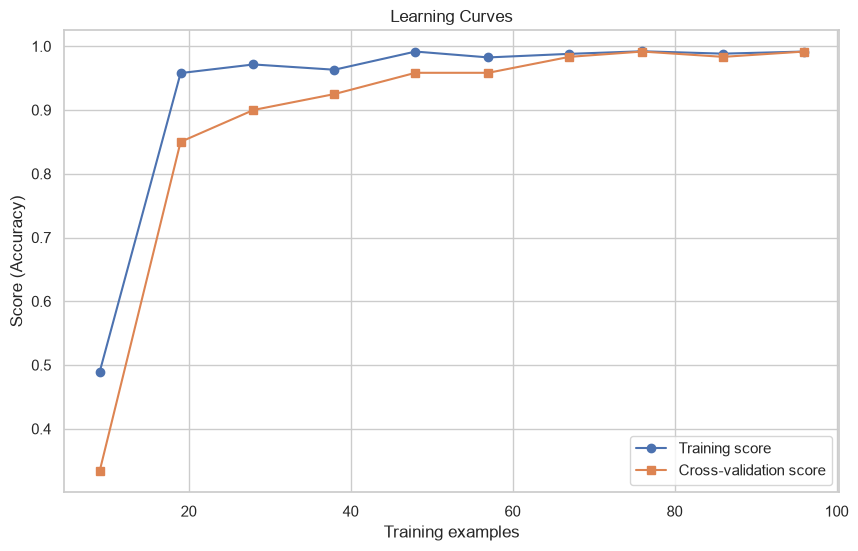

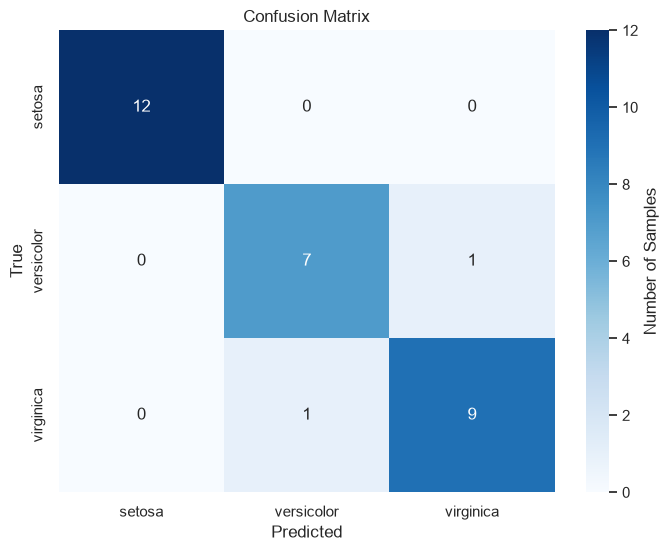


Classification Report:


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12
versicolor,0.875,0.875,0.875,8
virginica,0.900,0.900,0.900,10
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.925,0.925,30
weighted avg,0.933,0.933,0.933,30


In [17]:
# 1) Skor cross-validation
cv_scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=5)
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

# 2) Learning curve
train_sizes, train_scores, test_scores = learning_curve(
    grid_search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5
)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', label='Training score')
plt.plot(train_sizes, np.mean(test_scores, axis=1), 's-', label='Cross-validation score')
plt.xlabel('Training examples')
plt.ylabel('Score (Accuracy)')
plt.legend(loc='best')
plt.title('Learning Curves')
plt.show()

# 3) Prediksi pada test set + confusion matrix
y_pred = grid_search.best_estimator_.predict(X_test)
class_names = iris.target_names

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification report sebagai dict -> DataFrame agar lebih mudah dibaca
report_dict = classification_report(y_test, y_pred,
                                    target_names=class_names,
                                    output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()

styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print("\nClassification Report:")
display(styled_df)

**Interpretasi:** Kelima skor CV model terbaik adalah [0,958; 1; 1; 1; 1] dengan rata-rata **0,992** dan simpangan baku hanya **0,017** — model stabil di berbagai pembagian data. *Learning curve* memperlihatkan skor validasi naik tajam dari ~0,33 (9 sampel latih, terlalu sedikit untuk $k=9$ sehingga model hampir hanya menebak kelas mayoritas) ke ~0,96 pada ~50 sampel, lalu mendatar di sekitar 0,98–0,99 bersama skor latih. Kedua kurva konvergen di nilai tinggi dengan celah kecil: tidak ada indikasi overfitting maupun underfitting, dan menambah data hanya memberi manfaat kecil. Pada test set, model mencapai **accuracy 0,933** (28/30). Confusion matrix menunjukkan semua 12 *setosa* benar, sedangkan satu *versicolor* diprediksi *virginica* dan satu *virginica* diprediksi *versicolor*. Classification report: setosa precision/recall/F1 = 1,000; versicolor 0,875; virginica 0,900; macro avg ≈ 0,925 dan weighted avg ≈ 0,933. Nilai sempurna pada setosa bukan tanda overfitting, melainkan karena kelas ini memang terpisah linear dari dua kelas lain di ruang fitur; kesulitan sebenarnya hanya pada batas versicolor–virginica. Skor CV (0,992) sedikit lebih tinggi dari skor test (0,933) — wajar karena test set hanya 30 sampel, sehingga satu kesalahan sudah mengubah akurasi sebesar 3,3 poin.

## Latihan — Practical Exercises with KNN Models

Bagian ini mereproduksi solusi dari notebook *Exercise Solution* Chapter 4. Ketiga latihan merangkum seluruh alur kerja chapter: memuat data → preprocessing (split + scaling) → melatih KNN → tuning → evaluasi.

### Exercise 1: Membangun KNN Classifier (klasifikasi biner)

**Teori:** Dataset **Breast Cancer Wisconsin** berisi 569 sampel dengan 30 fitur numerik hasil pengukuran citra inti sel (radius, tekstur, luas, dsb.) dan target biner (0 = *malignant*, 1 = *benign*). Rentang fitur sangat berbeda (mis. *mean area* ratusan hingga ribuan, *mean smoothness* sekitar 0,1), sehingga **StandardScaler** wajib dipakai sebelum KNN agar jarak Euclidean tidak didominasi fitur berskala besar. Scaler di-*fit* pada data latih saja, lalu dipakai untuk mentransformasi data uji. Dalam konteks medis, *recall* kelas malignant (seberapa banyak kanker yang tertangkap) biasanya lebih penting daripada akurasi total.

In [18]:
# Memuat library
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Memuat dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Preprocessing: split data latih/uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling fitur (fit hanya pada data latih)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Membuat dan melatih KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Prediksi
y_pred = knn.predict(X_test_scaled)

# Evaluasi performa
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# (Tambahan) pembanding: KNN tanpa scaling
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print(f"(Pembanding) Accuracy tanpa scaling: {accuracy_score(y_test, knn_raw.predict(X_test)):.3f}")

Accuracy: 0.947

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

(Pembanding) Accuracy tanpa scaling: 0.956


**Interpretasi:** KNN ($k=5$) dengan fitur terstandardisasi mencapai **accuracy 0,947** pada 114 sampel uji. Precision dan recall kelas *malignant* sama-sama 0,93 (sekitar 3 dari 43 kasus kanker terlewat), sedangkan *benign* 0,96. Macro avg (0,94) sedikit di bawah weighted avg (0,95) karena kelas malignant yang lebih kecil memiliki skor lebih rendah. Menariknya, pembanding tanpa scaling justru memberi 0,956 pada split ini. Hal ini tidak membantah pentingnya scaling: test set kecil (selisih 1 sampel = 0,9 poin) membuat perbandingan satu split tidak konklusif, dan beberapa fitur berskala besar (radius/area/perimeter) kebetulan sangat informatif untuk dataset ini. Kesimpulan yang tepat harus diambil lewat cross-validation, dan secara prinsip scaling tetap praktik standar untuk model berbasis jarak.

### Exercise 2: Tuning Hyperparameter dengan Grid Search

**Teori:** Latihan ini memakai dataset sintetis `make_classification` (1000 sampel, 20 fitur: 15 informatif + 5 redundan, 3 kelas). Fitur *redundan* adalah kombinasi linear dari fitur informatif — tidak menambah informasi baru tetapi tetap ikut dihitung dalam jarak, sehingga memberi bobot berlebih pada arah tertentu. Dengan 20 dimensi, efek *curse of dimensionality* mulai terasa, sehingga pemilihan $k$, skema bobot, dan metrik melalui `GridSearchCV` menjadi penting. Grid yang sama dengan resep 4.3 dipakai (20 kombinasi × 5 fold).

*Catatan praktik baik:* pada kode asli scaler di-*fit* pada seluruh data latih sebelum CV, sehingga ada kebocoran kecil statistik (mean/std) dari fold validasi. Cara yang lebih bersih adalah membungkus `StandardScaler` + KNN dalam `Pipeline` di dalam `GridSearchCV`; versi tersebut ditampilkan sebagai pembanding.

In [19]:
# Memuat library
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Memuat dataset lain (sintetis, 3 kelas)
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15,
                           n_redundant=5, n_classes=3, random_state=42)

# Preprocessing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Menyiapkan grid search
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
knn = KNeighborsClassifier()
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')

# Fit grid search
grid_search.fit(X_train_scaled, y_train)

# Evaluasi model terbaik
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)
y_pred = grid_search.predict(X_test_scaled)
print("\nTest Set Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.8574999999999999

Test Set Performance:
Accuracy: 0.88

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.86      0.89        70
           1       0.91      0.96      0.93        73
           2       0.79      0.81      0.80        57

    accuracy                           0.88       200
   macro avg       0.88      0.87      0.87       200
weighted avg       0.88      0.88      0.88       200



In [20]:
# (Tambahan) Versi tanpa leakage: scaler berada di dalam Pipeline
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
pipe_grid = {f"kneighborsclassifier__{k}": v for k, v in param_grid.items()}
gs_pipe = GridSearchCV(pipe, pipe_grid, cv=5, scoring='accuracy').fit(X_train, y_train)
print("Best parameters (Pipeline):", gs_pipe.best_params_)
print("Best CV score (Pipeline)  :", round(gs_pipe.best_score_, 4))
print("Test accuracy (Pipeline)  :", accuracy_score(y_test, gs_pipe.predict(X_test)))

Best parameters (Pipeline): {'kneighborsclassifier__metric': 'euclidean', 'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'distance'}
Best CV score (Pipeline)  : 0.8562
Test accuracy (Pipeline)  : 0.865


**Interpretasi:** Grid search memilih **Euclidean, $k=9$, `uniform`** dengan CV accuracy **0,857**, dan pada test set menghasilkan **accuracy 0,880**. Per kelas, kelas 1 paling mudah (recall 0,96), sedangkan kelas 2 paling sulit (precision 0,79, recall 0,81) — kelas ini paling banyak tumpang-tindih dengan kelas lain di ruang 20 dimensi. Versi **Pipeline** (scaler di-*fit* ulang per fold) memilih kombinasi berbeda ($k=7$, `distance`) dengan skor CV hampir sama (0,856) dan test accuracy 0,865. Perbedaan kecil ini menunjukkan: (1) leakage dari scaling pada kasus ini dampaknya kecil, tetapi bisa mengubah pilihan hyperparameter; (2) banyak kombinasi hyperparameter memiliki performa yang secara statistik setara, sehingga selisih 1–2 poin di test set (200 sampel) tidak perlu dianggap signifikan.

### Exercise 3: Mengevaluasi KNN Classifier

**Teori:** Latihan terakhir menerapkan teknik evaluasi dari resep 4.4 pada dataset sintetis 3 kelas yang lebih sulit: 15 fitur (10 informatif, 5 redundan) dan `n_clusters_per_class=2`, artinya setiap kelas tersusun dari dua klaster Gaussian yang terpisah. Struktur multi-modal seperti ini sebenarnya cocok untuk KNN (karena KNN bersifat lokal dan tidak mengasumsikan satu pusat per kelas), tetapi klaster yang saling tumpang-tindih menimbulkan salah klasifikasi. Evaluasi dilakukan dengan accuracy, confusion matrix, dan classification report (precision/recall/F1 per kelas).

Model Performance Evaluation
------------------------------
Accuracy Score: 0.850

Confusion Matrix:
[[56  6  6]
 [ 4 56  5]
 [ 6  3 58]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.82      0.84        68
           1       0.86      0.86      0.86        65
           2       0.84      0.87      0.85        67

    accuracy                           0.85       200
   macro avg       0.85      0.85      0.85       200
weighted avg       0.85      0.85      0.85       200



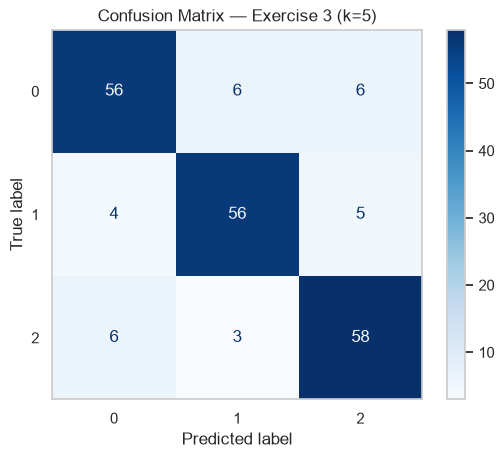

In [21]:
# Memuat library
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Memuat dataset sintetis 3 kelas dengan fitur informatif/redundan
X, y = make_classification(n_samples=1000,
                           n_features=15,
                           n_informative=10,
                           n_redundant=5,
                           n_classes=3,
                           n_clusters_per_class=2,
                           random_state=42)

# Preprocessing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Membuat dan melatih KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Prediksi
y_pred = knn.predict(X_test_scaled)

# Evaluasi performa
print("Model Performance Evaluation")
print("-" * 30)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# (Tambahan) visualisasi confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Confusion Matrix — Exercise 3 (k=5)')
plt.grid(False)
plt.show()

**Interpretasi:** Dengan $k=5$ tanpa tuning, model mencapai **accuracy 0,850** pada 200 sampel uji. Confusion matrix memperlihatkan diagonal 56/56/58 dengan kesalahan tersebar cukup merata di semua pasangan kelas (3–6 sampel per sel di luar diagonal), sehingga tidak ada satu pasangan kelas yang sangat membingungkan model. Precision, recall, dan F1 semua kelas berada di kisaran 0,82–0,87, dan macro avg sama dengan weighted avg (0,85) karena kelasnya seimbang (68/65/67). Akurasi yang lebih rendah dibanding Exercise 2 disebabkan dataset yang lebih sulit (setiap kelas terdiri dari dua klaster dan fitur informatif lebih sedikit). Langkah perbaikan yang wajar adalah tuning $k$/metrik/bobot seperti Exercise 2 atau seleksi fitur untuk membuang dimensi redundan.

## Ringkasan Chapter 4

1. **KNN adalah model non-parametrik berbasis instance.** Tidak ada parameter yang dipelajari; prediksi dibuat dengan mencari $k$ titik latih terdekat lalu melakukan *majority vote* (klasifikasi) atau rata-rata (regresi). Proporsi suara tetangga merupakan estimasi lokal dari posterior $P(y=c\mid\mathbf{x})$, dan secara teoretis error 1-NN asimtotik paling buruk sekitar dua kali error Bayes.
2. **Hyperparameter $k$ mengendalikan bias–variance.** $k$ kecil → batas keputusan berliku (variance tinggi); $k$ besar → batas halus (bias tinggi). Validation curve dan grid search membantu menemukan titik keseimbangan.
3. **Metrik jarak menentukan arti "dekat".** Minkowski $L_p$ merangkum Manhattan ($p=1$), Euclidean ($p=2$), dan Chebyshev ($p=\infty$); cosine mengukur perbedaan arah; Mahalanobis memperhitungkan korelasi. Di scikit-learn, `metric='minkowski'` dengan `p=2` identik dengan Euclidean. Metrik yang cocok dengan geometri data (radial vs sejajar sumbu) dapat memperbaiki performa, tetapi perbedaan pada test set kecil perlu dikonfirmasi dengan cross-validation.
4. **Feature scaling adalah keharusan.** Karena jarak menjumlahkan selisih antar fitur, fitur berskala besar akan mendominasi. `StandardScaler` (idealnya di dalam `Pipeline` agar tidak terjadi *data leakage*) memulihkan kontribusi setara tiap fitur — terlihat dari penurunan akurasi drastis saat satu fitur Iris diperbesar 1000× dan pemulihannya setelah scaling.
5. **Curse of dimensionality** membuat jarak kehilangan daya pembeda pada dimensi tinggi (kontras $d_{\max}/d_{\min}$ mendekati 1), sehingga KNN perlu seleksi fitur/reduksi dimensi pada data berdimensi besar.
6. **Efisiensi pencarian tetangga:** brute force $O(np)$ per query; KD-Tree (partisi sejajar sumbu) sangat cepat di dimensi rendah; Ball-Tree (hipersfer + ketidaksamaan segitiga) lebih tahan di dimensi menengah. Semua memberi hasil eksak yang sama; `algorithm='auto'` memilih secara otomatis.
7. **Bobot jarak (`weights='distance'`)** memberi tetangga yang lebih dekat pengaruh lebih besar ($w_i=1/d_i$), membuat model lebih robust terhadap pilihan $k$ besar, namun selalu sempurna di data latih sehingga evaluasi harus pada data terpisah.
8. **Tuning dengan `GridSearchCV`** mencoba semua kombinasi hyperparameter dengan K-fold cross-validation; test set disisihkan untuk estimasi akhir.
9. **Evaluasi menyeluruh** memakai cross-validation (rata-rata + simpangan baku), learning curve (diagnosis bias/variance dan kebutuhan data), confusion matrix, serta precision/recall/F1 per kelas dengan macro/weighted average.
10. **Kelebihan & keterbatasan KNN:** sederhana, tanpa asumsi distribusi, alami untuk multi-kelas dan batas non-linear; tetapi prediksi lambat dan boros memori untuk data besar, sensitif terhadap skala, fitur tidak relevan, dan dimensi tinggi. Konsep jarak yang dipelajari di sini juga menjadi fondasi metode lain seperti K-Means, DBSCAN, dan sistem rekomendasi berbasis kemiripan.